In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

from config import Config
from event_mapping import EVENT_MAPPING
from data_loader import load_lmd2022
from feature_engineering import (
    create_subset, drop_features, engineer_features, h, SUBSET_N_ROWS
)
from feature_selection import run_feature_selection_pipeline
from plotting import (
    setup_plot_style,
    plot_class_distribution,
    plot_event_counts,
    plot_mi_encoded,
    plot_all_selection_charts,
)

setup_plot_style()
%matplotlib inline

In [2]:
print(f"Config.LMD_2022_PATH: {Config.LMD_2022_PATH}")

Config.LMD_2022_PATH: /home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/data/lmd2022/LMD-2022_NormalVsMalicious.csv


In [3]:
lmd2022_df = load_lmd2022(Config.LMD_2022_PATH)

Useful columns (excluding Unnamed): 94
Rows after filtering valid labels: 293,548
Columns: 94

Label distribution:
isMalicious
1    191194
0    102354
Name: count, dtype: int64
isMalicious
1    65.132108
0    34.867892
Name: proportion, dtype: float64


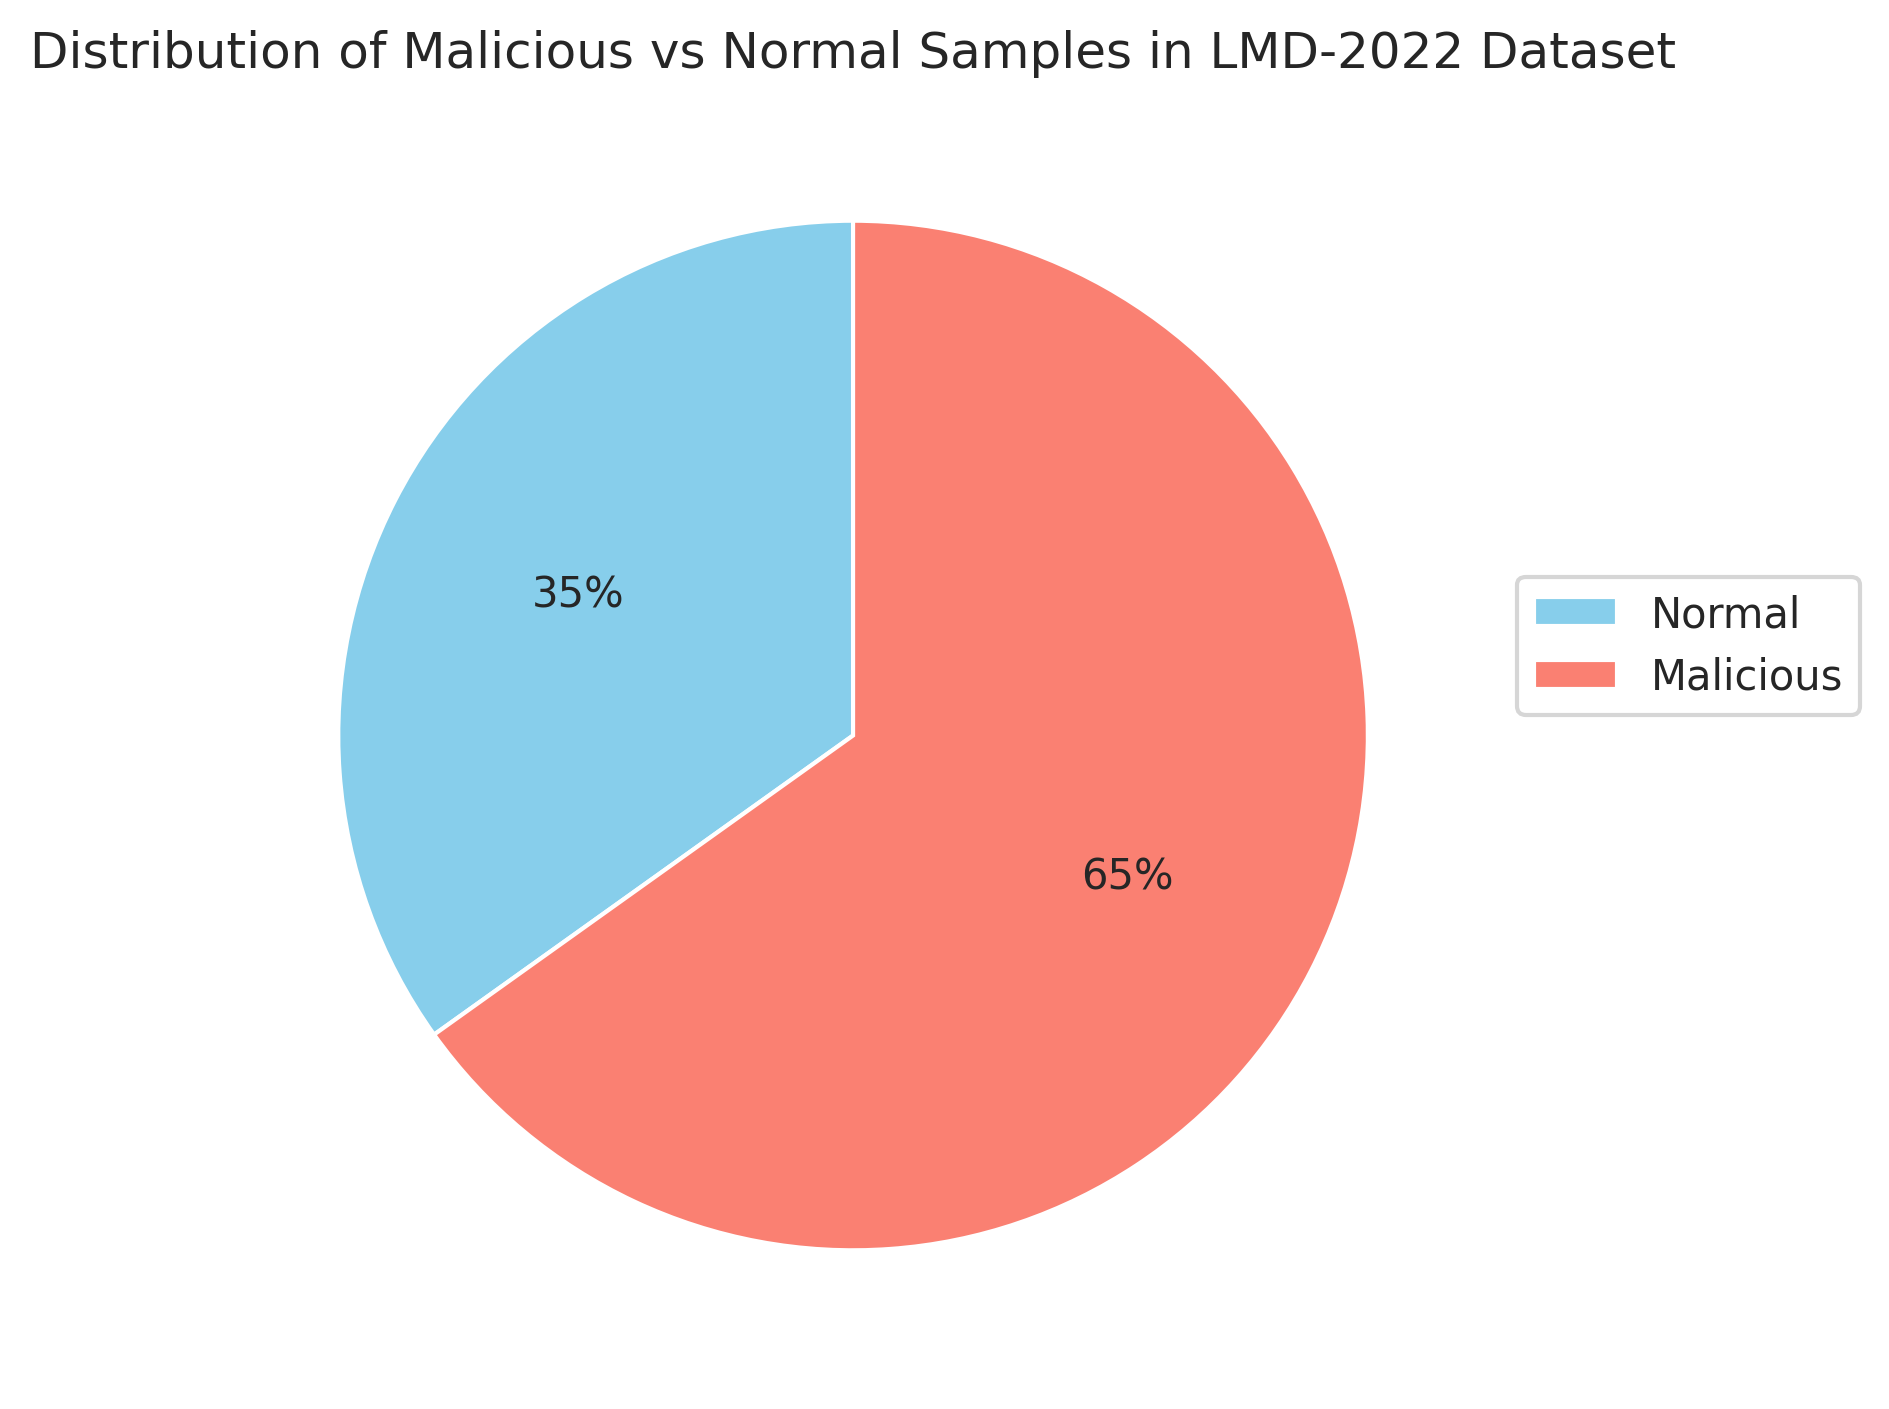

In [4]:
plot_class_distribution(lmd2022_df)

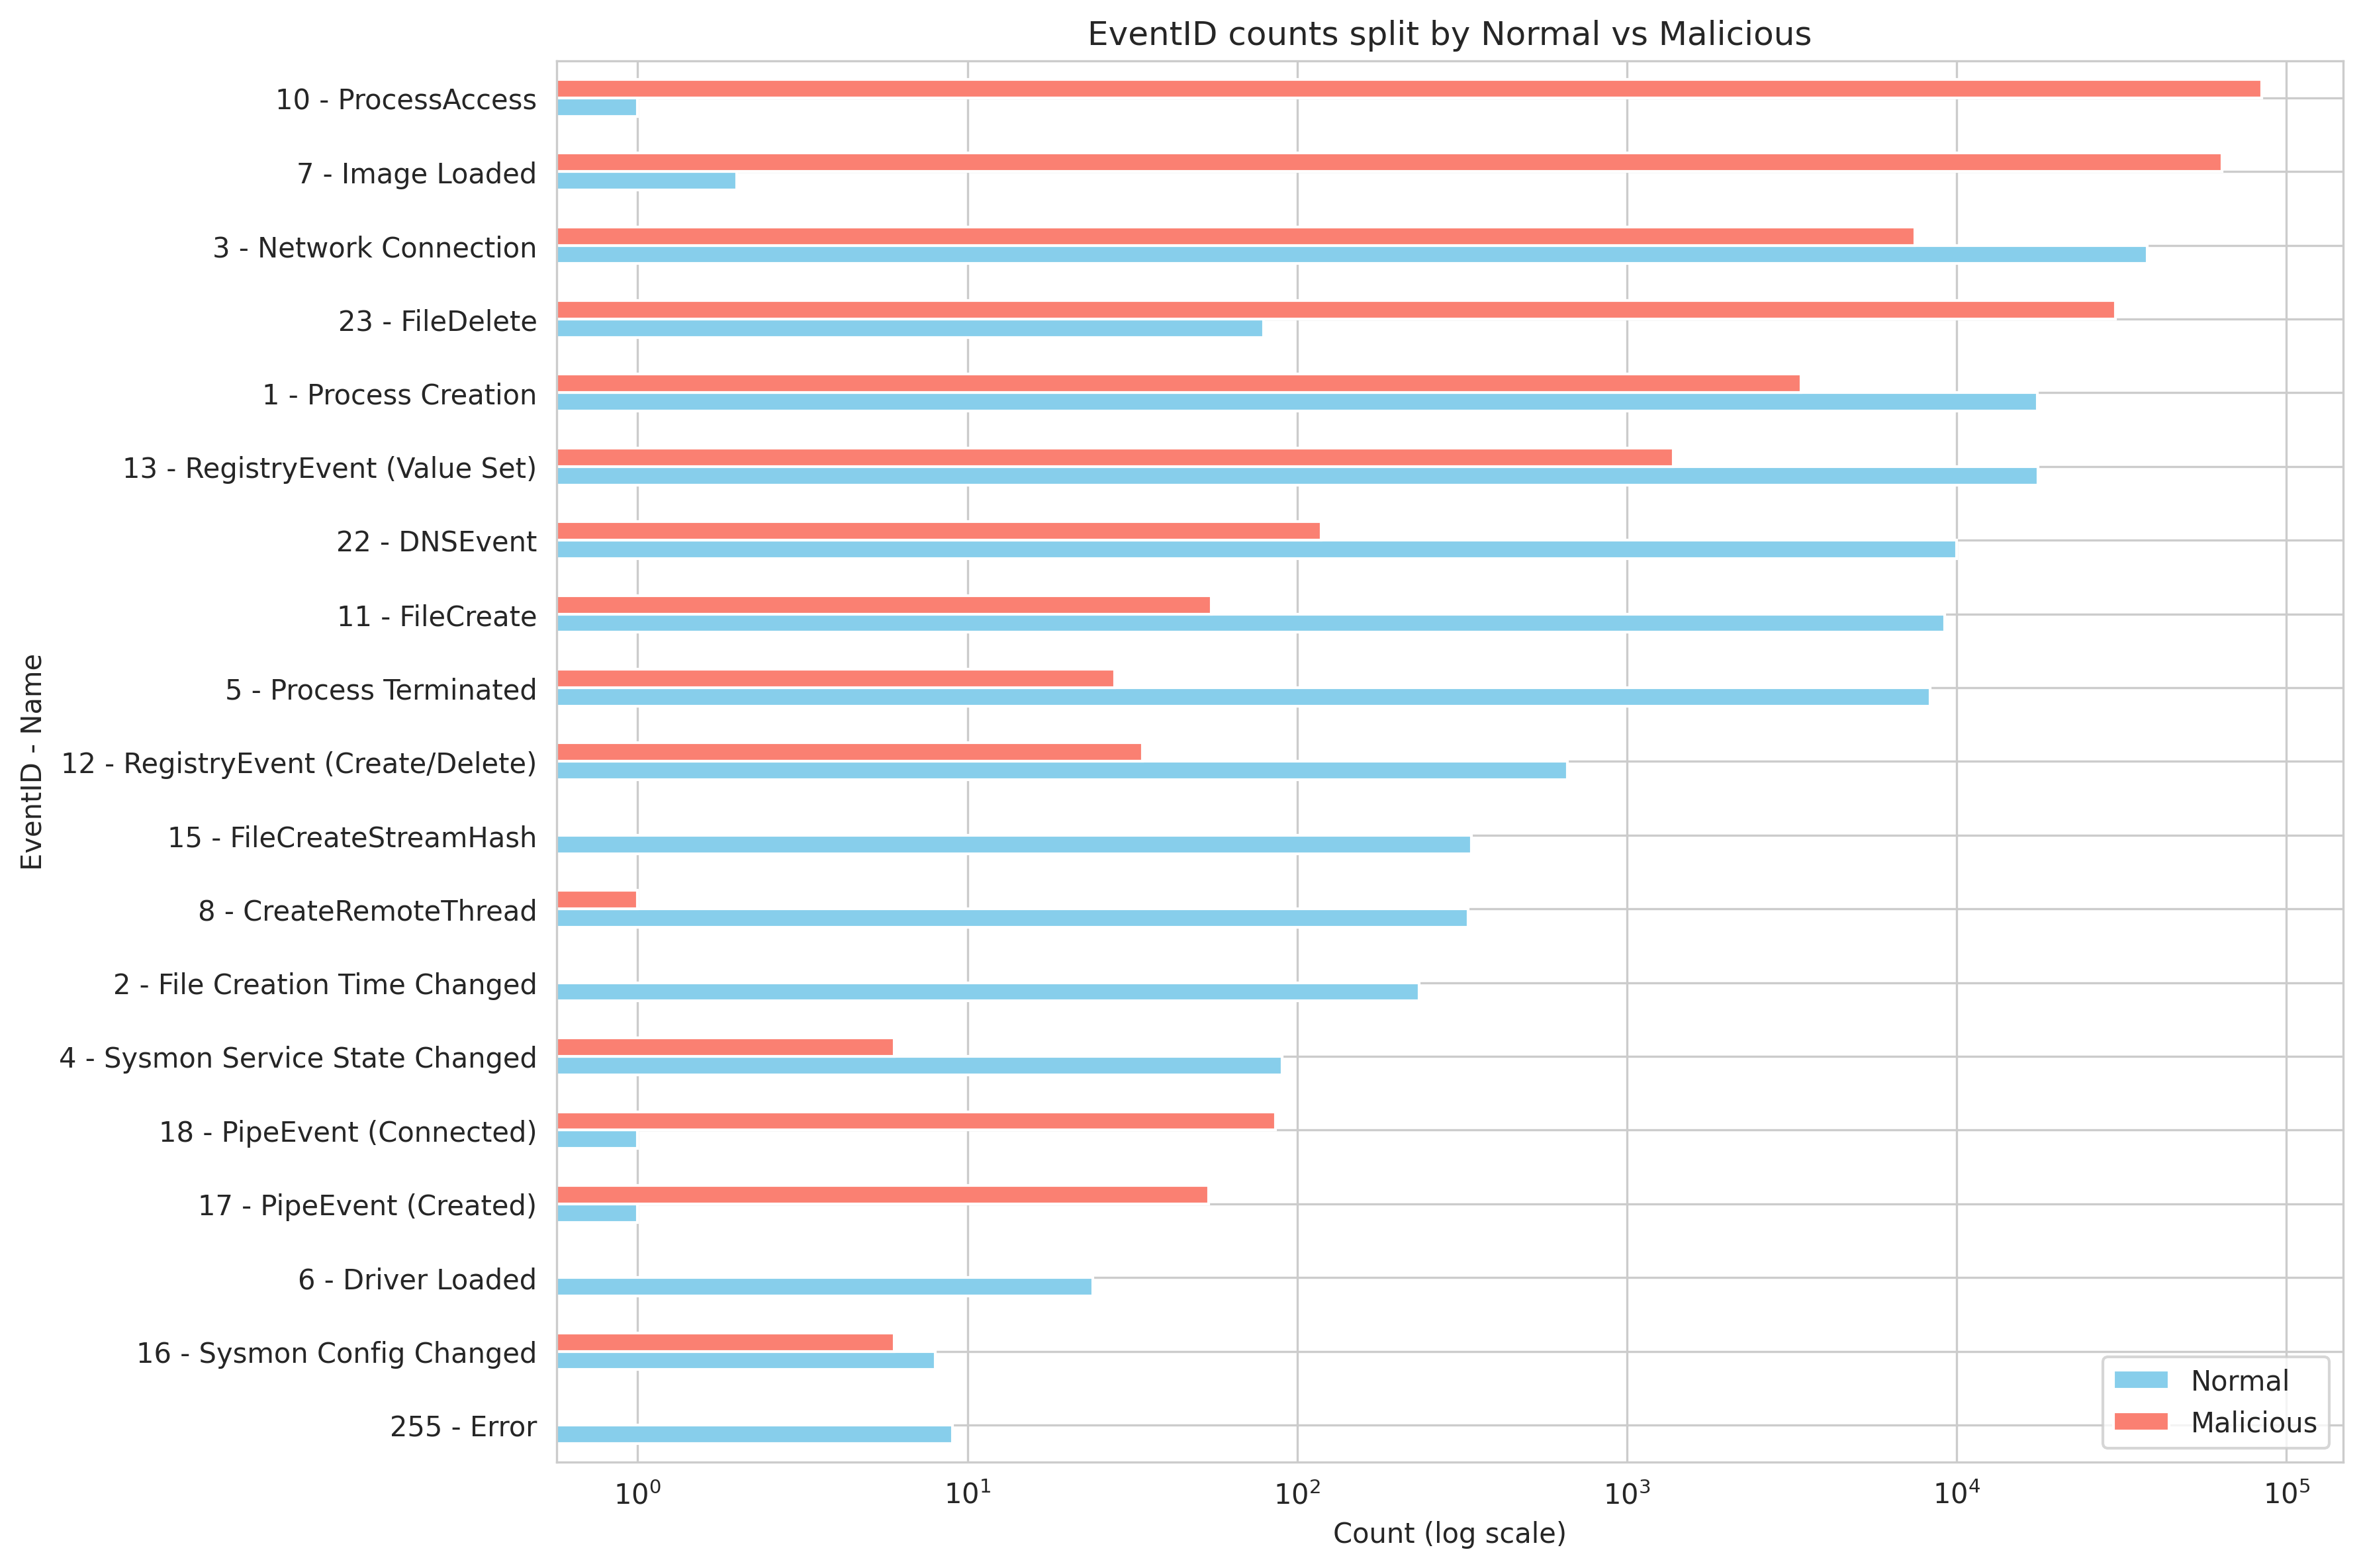

In [5]:
plot_event_counts(lmd2022_df, EVENT_MAPPING)

In [6]:
# Section 0: Optional stratified subset
df = create_subset(lmd2022_df, subset_n_rows=SUBSET_N_ROWS)


SECTION 0: LOAD DATA
Stratified subset: 50,000 rows from 293,548

Label distribution:
isMalicious
1    32566
0    17434
Name: count, dtype: int64
isMalicious
1    65.13
0    34.87
Name: proportion, dtype: float64

Computers: 8


In [7]:
# Section 1: Drop constants, identifiers, and leak-prone features
df_clean, all_drops, cols_before = drop_features(df)


SECTION 1: FEATURE REMOVAL (STATISTICALLY JUSTIFIED)

1a. Near-zero variance (15 features):
    Channel
    Configuration
    ConfigurationFileHash
    Correlation
    Execution_ProcessID
    ID
    Keywords
    Level
    Name
    Opcode
    PipeName
    SchemaVersion
    State
    UserID
    Version2

1b. Metadata / identifiers (25 features):
    CreationUtcTime
    EventRecordID
    Execution_ProcessID
    Guid
    LogonGuid
    Name
    ParentProcessGuid
    PreviousCreationUtcTime
    ProcessGuid
    ProcessID
    ProcessId
    SourceProcessGUID
    SourceProcessGuid
    SourceProcessId
    SourceThreadId
    StartFunction
    SystemTime
    TargetProcessGUID
    TargetProcessGuid
    TargetProcessId
    ThreadID
    User
    UserID
    UtcTime
    Version

1c. High-cardinality leak risk (11 features):
    CallTrace
    CommandLine
    ConfigurationFileHash
    Contents
    Details
    Hash
    Hashes
    ParentCommandLine
    QueryResults
    TargetFilename
    TargetObject

1d. 

In [8]:
# Section 2: Feature engineering
X, y, groups = engineer_features(df_clean)


SECTION 2: FEATURE ENGINEERING
✓ Image → Image_Category (6 categories)
✓ SourcePort → SourcePort_Bin (4 bins)
✓ DestinationPort → DestinationPort_Bin (4 bins)
✓ ImageLoaded: 186 → 46 categories (grouped 141 rare)
✓ ParentImage: 101 → 14 categories (grouped 88 rare)
✓ TargetImage: 81 → 28 categories (grouped 54 rare)
✓ SourceImage: 30 → 15 categories (grouped 16 rare)
✓ CurrentDirectory: 59 → 5 categories (grouped 55 rare)
✓ QueryName: 130 → 8 categories (grouped 123 rare)
✓ LogonId → LogonId_Populated (binary)
✓ Dropped ParentProcessId (identifier, 544 unique)

Final X shape: (50000, 41)
Categorical: 38
Numeric:     3


In [9]:
# Sections 3-9: Full feature selection pipeline
results = run_feature_selection_pipeline(X, y, groups, output_dir=".")


SECTION 3: GROUP-BASED TRAIN/VAL SPLIT
Train: 36,952 samples | Val: 13,048 samples
Train computers: ['LAPTOP-ROPR18AK', 'WINDOWS10EVAL.stefania.local', 'win-dc-128.attackrange.local', 'win-dc-469.attackrange.local', 'win-host-100.attackrange.local', 'win-host-987.attackrange.local']
Val computers:   ['WIN-J23NIGGP1Q6.sysmon_set.local', 'win-dc-800.attackrange.local']

Train label %:
isMalicious
1    72.69
0    27.31
Name: proportion, dtype: float64

Val label %:
isMalicious
0    56.28
1    43.72
Name: proportion, dtype: float64

SECTION 4: ONE-HOT ENCODING + VARIANCE FILTER
Categorical columns (38): ['RuleName', 'FileVersion', 'Description', 'Product', 'Company', 'OriginalFileName', 'CurrentDirectory', 'TerminalSessionId', 'IntegrityLevel', 'ParentImage', 'ParentUser', 'Protocol', 'Initiated', 'SourceIsIpv6', 'SourceIp', 'SourceHostname', 'SourcePortName', 'DestinationIp', 'DestinationHostname', 'DestinationPortName', 'ImageLoaded', 'Signed', 'Signature', 'SourceImage', 'TargetImage',

/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:123: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:123: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:125: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:125: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")


✓ Saved: 01_mutual_information_scores.png


/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


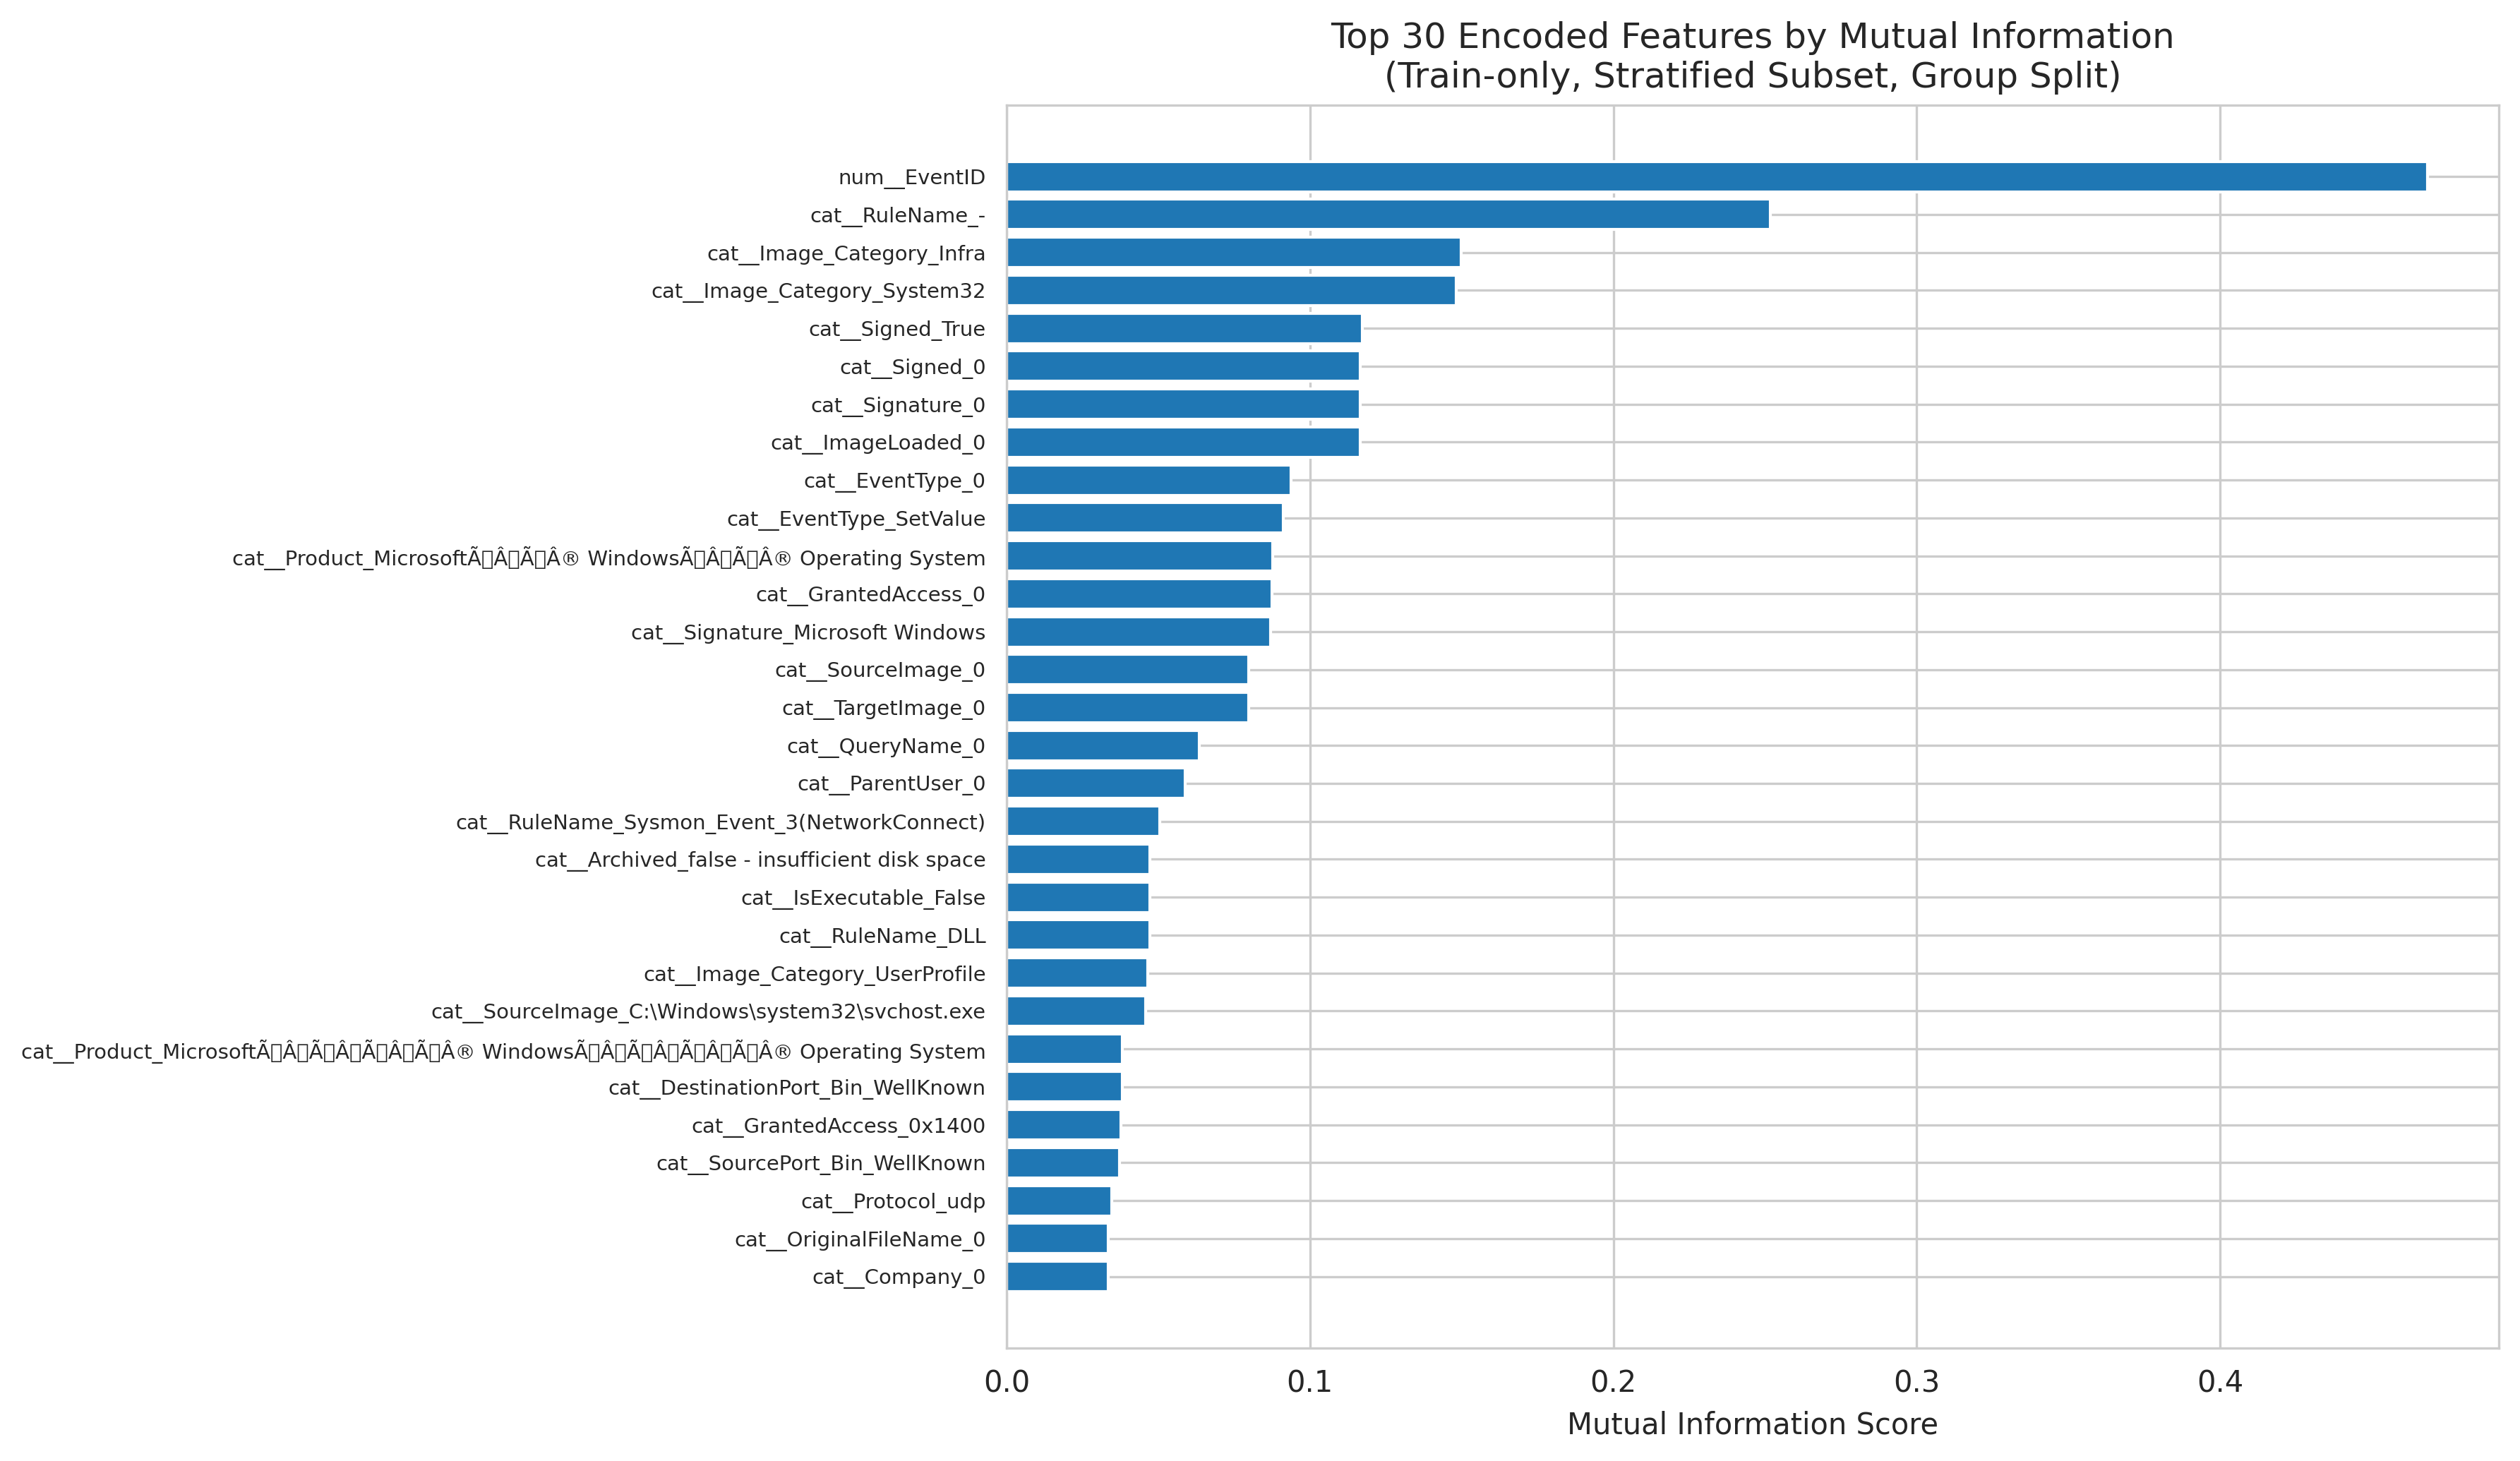

In [10]:
# MI plot from Section 5
plot_mi_encoded(
    results["mi_df"],
    title_suffix="(Train-only, Stratified Subset, Group Split)",
    save_path="01_mutual_information_scores.png",
)

✓ Saved: ./06_original_feature_importance.png


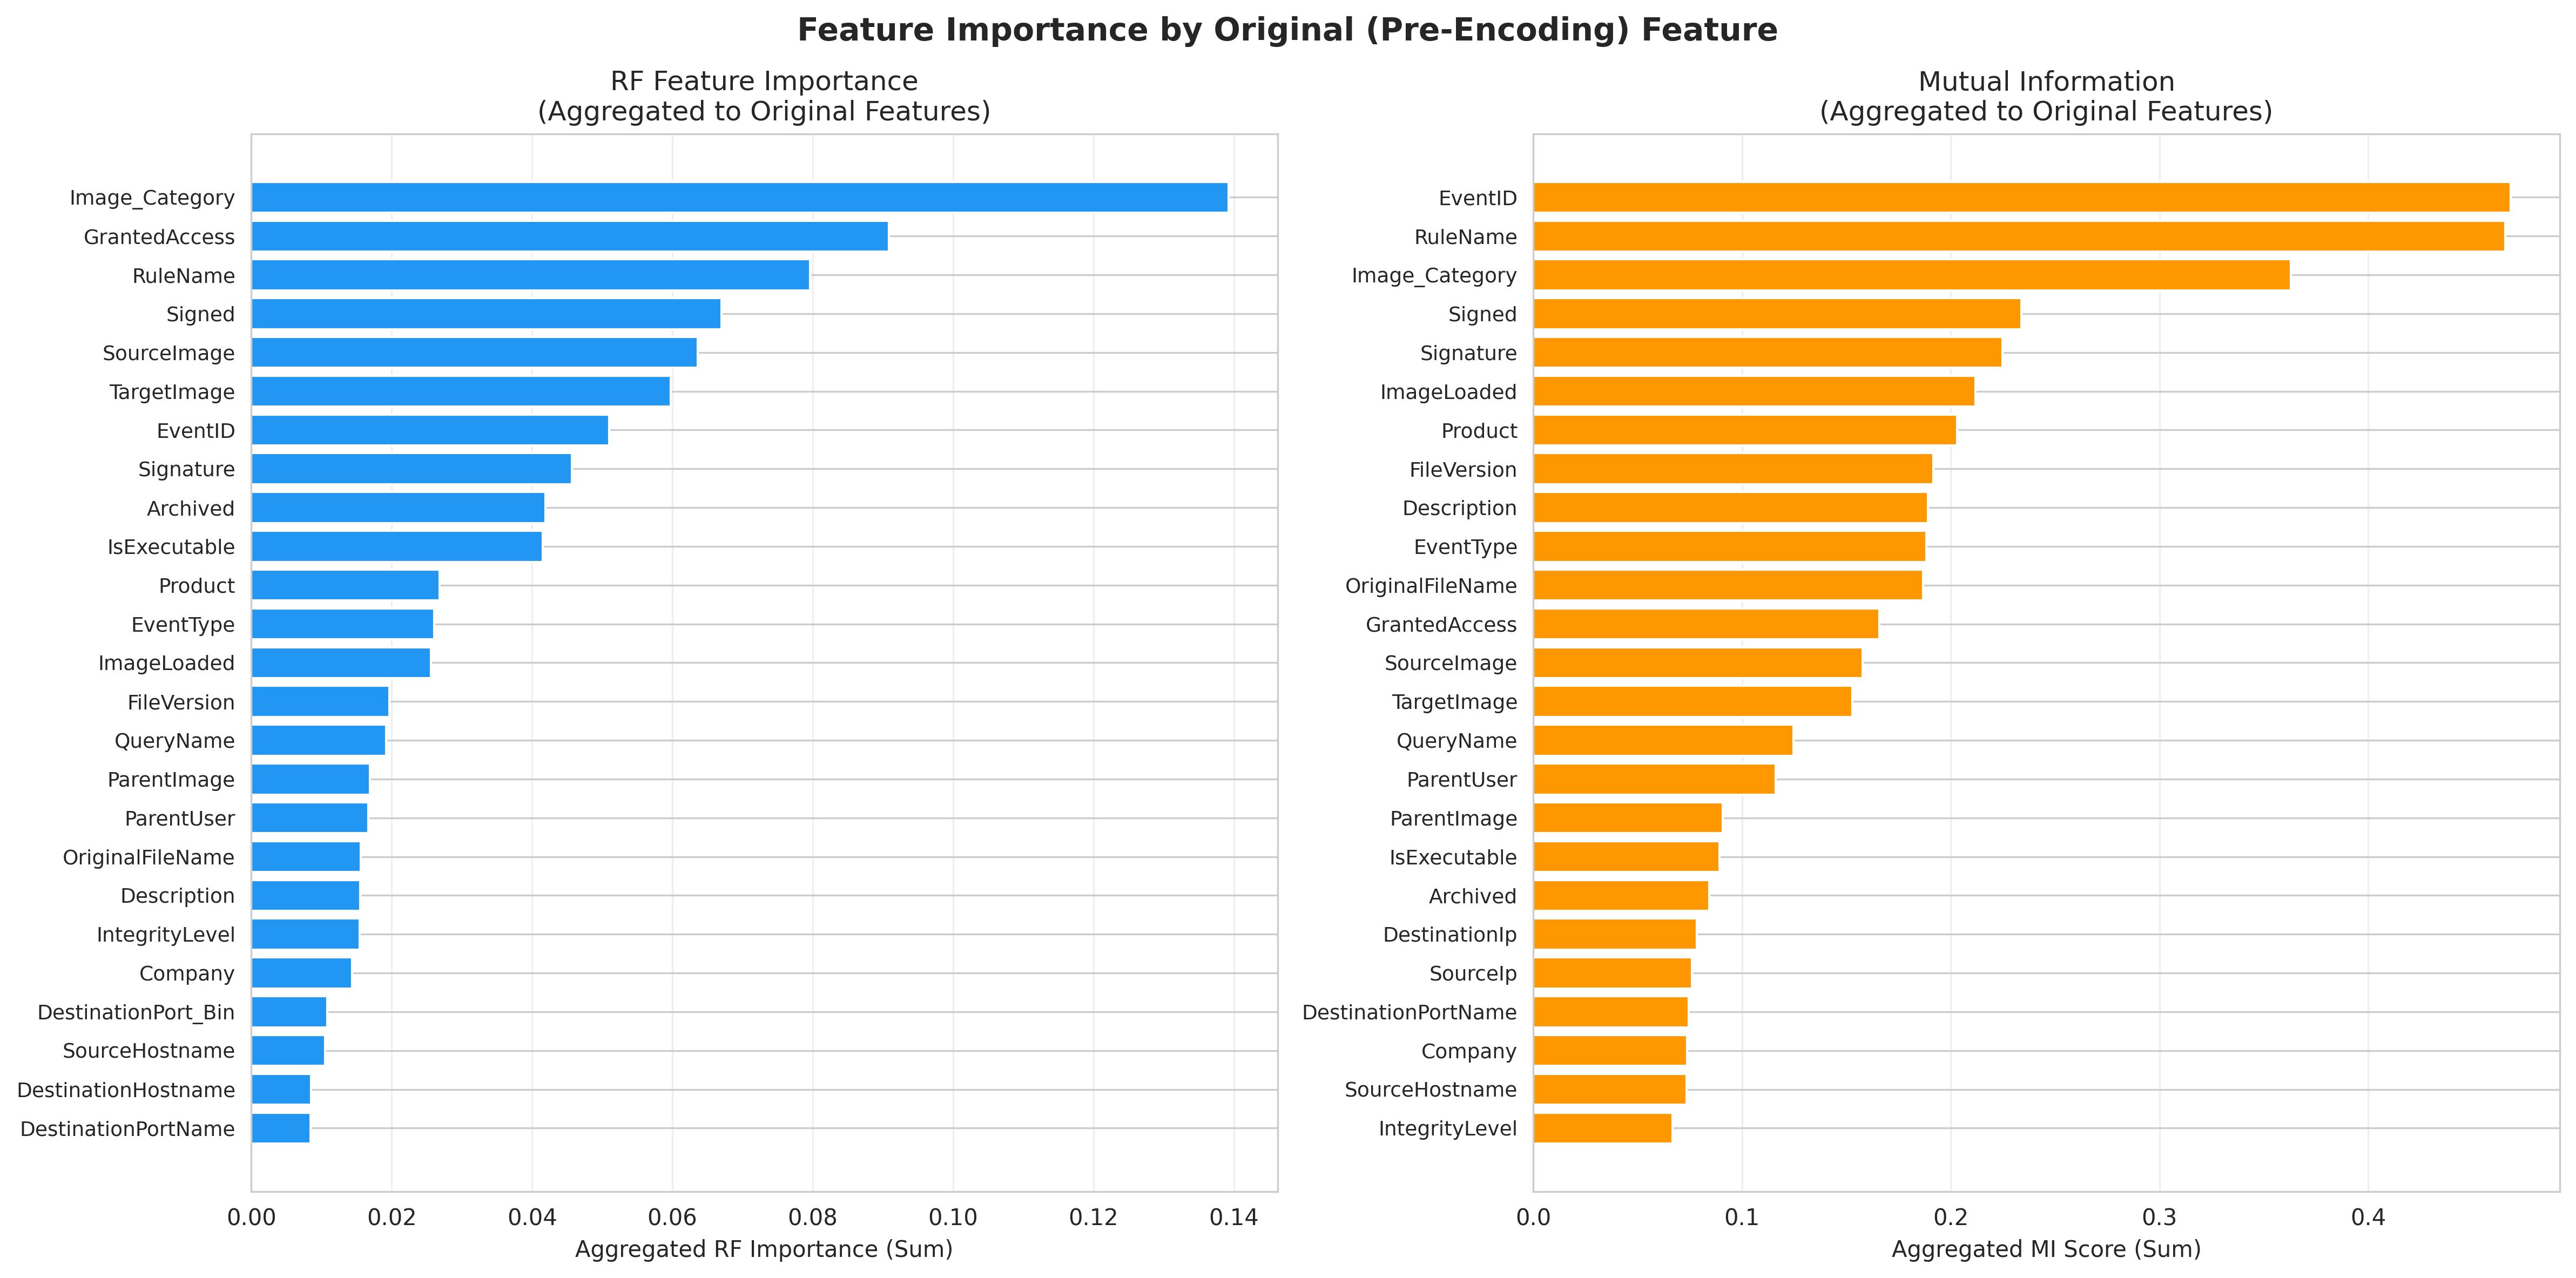

✓ Saved: ./07_performance_vs_features.png


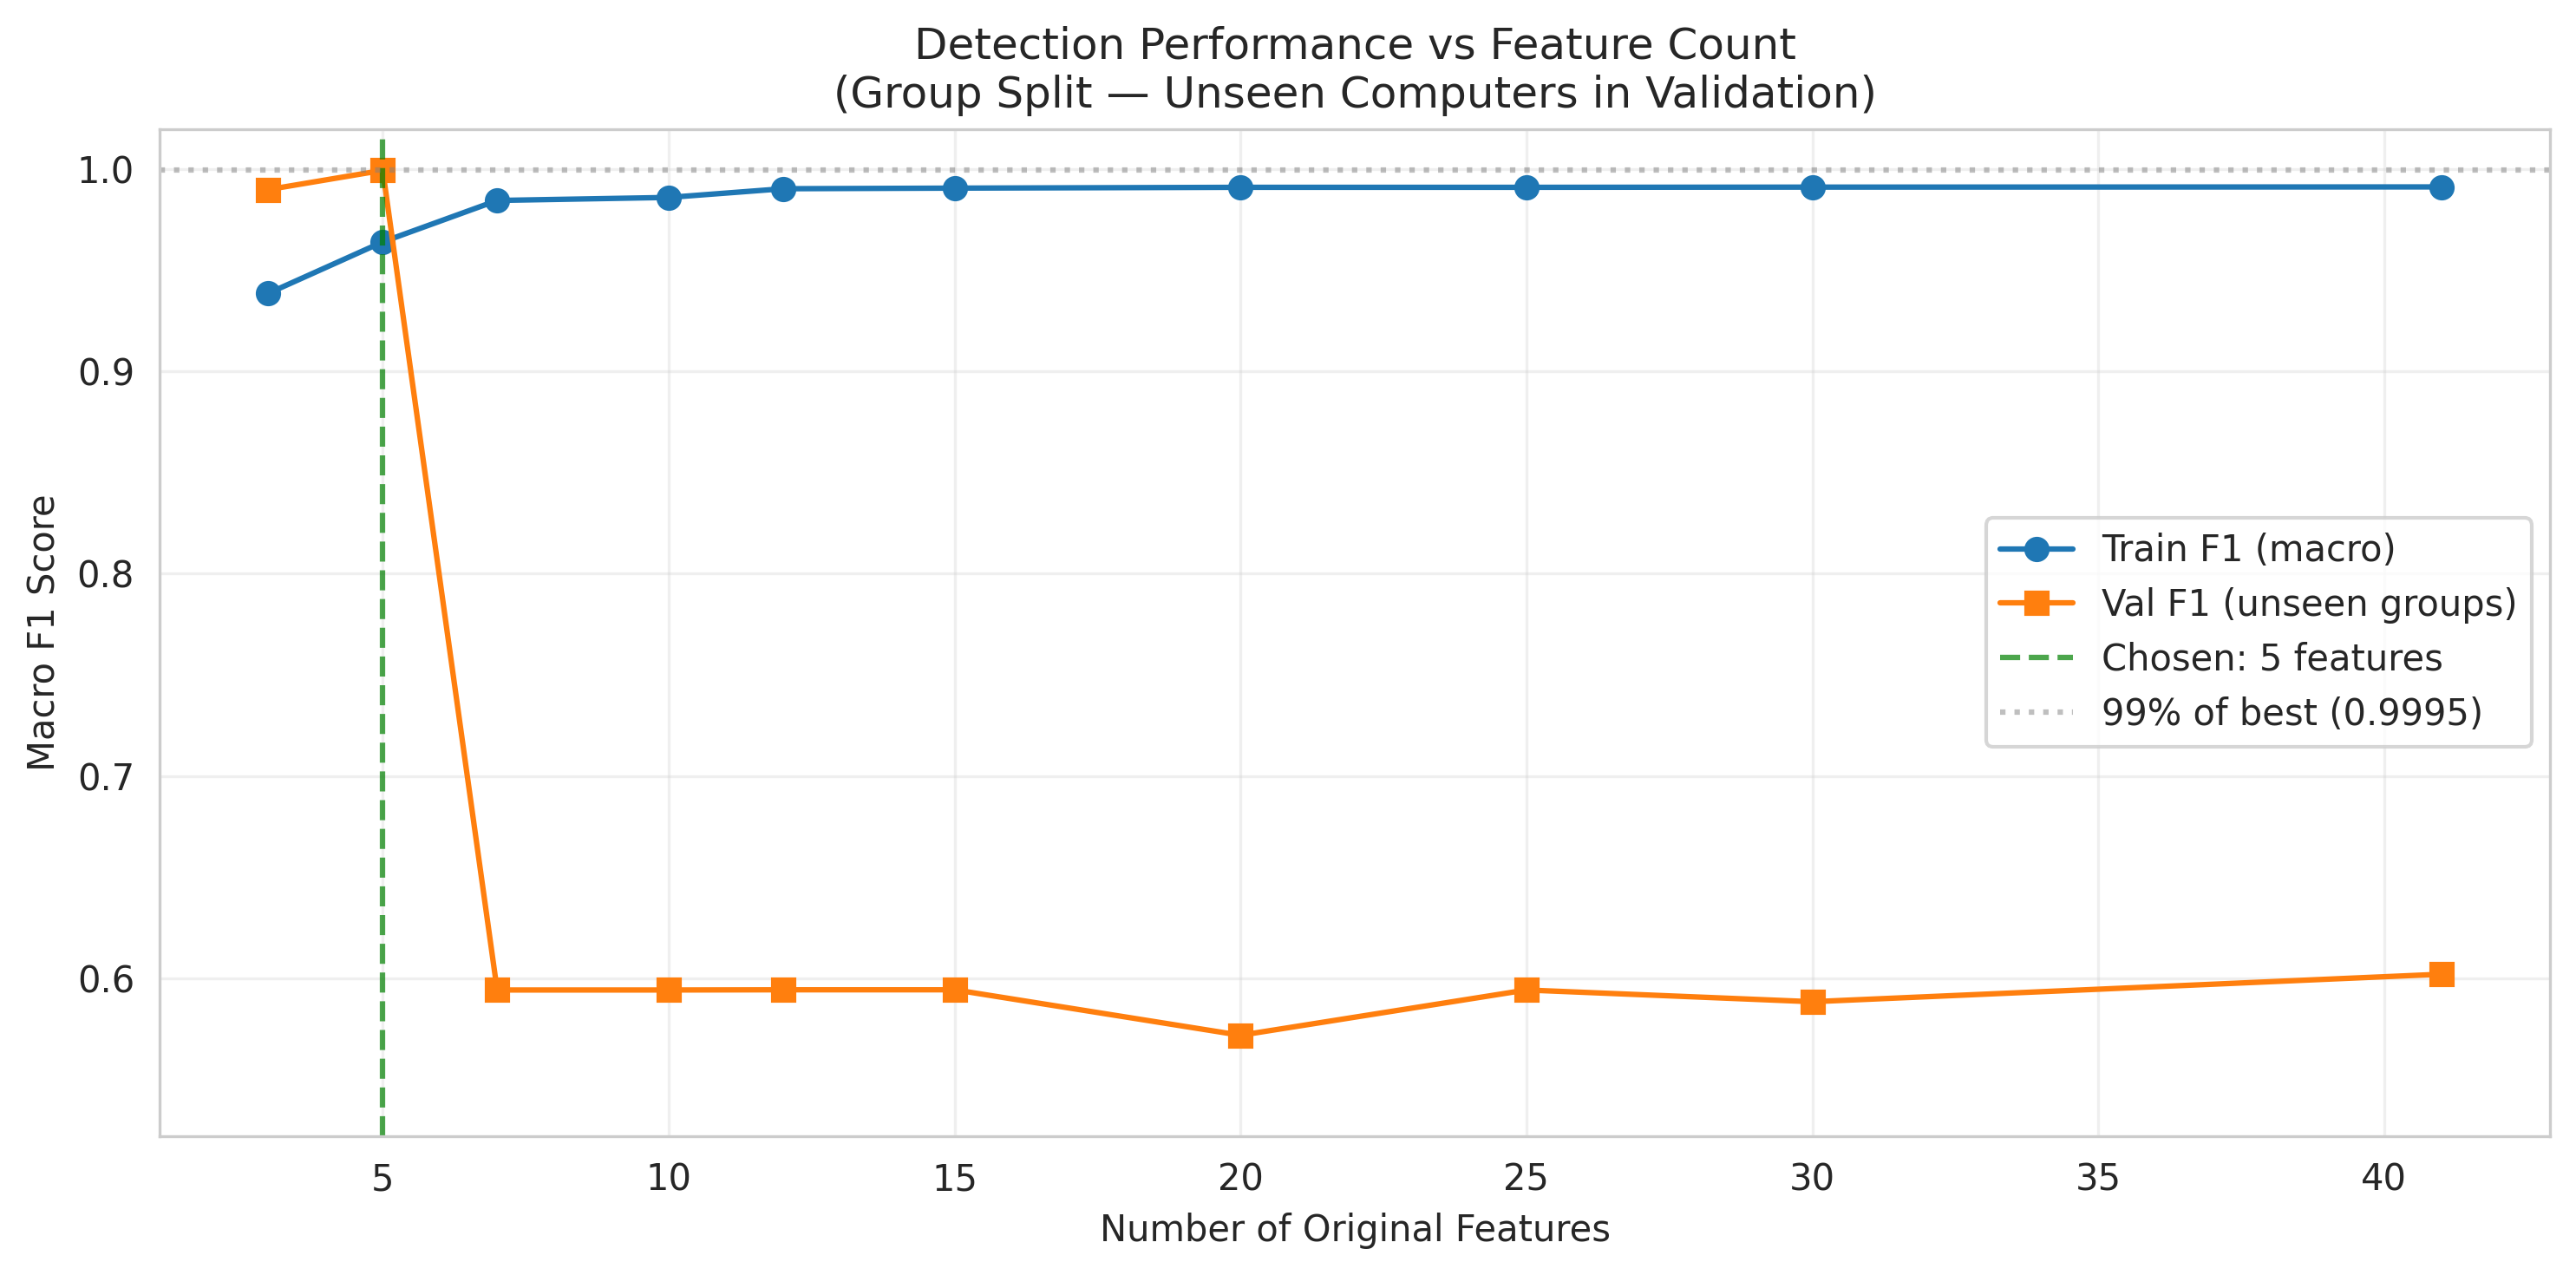

✓ Saved: ./08_overfit_gap.png


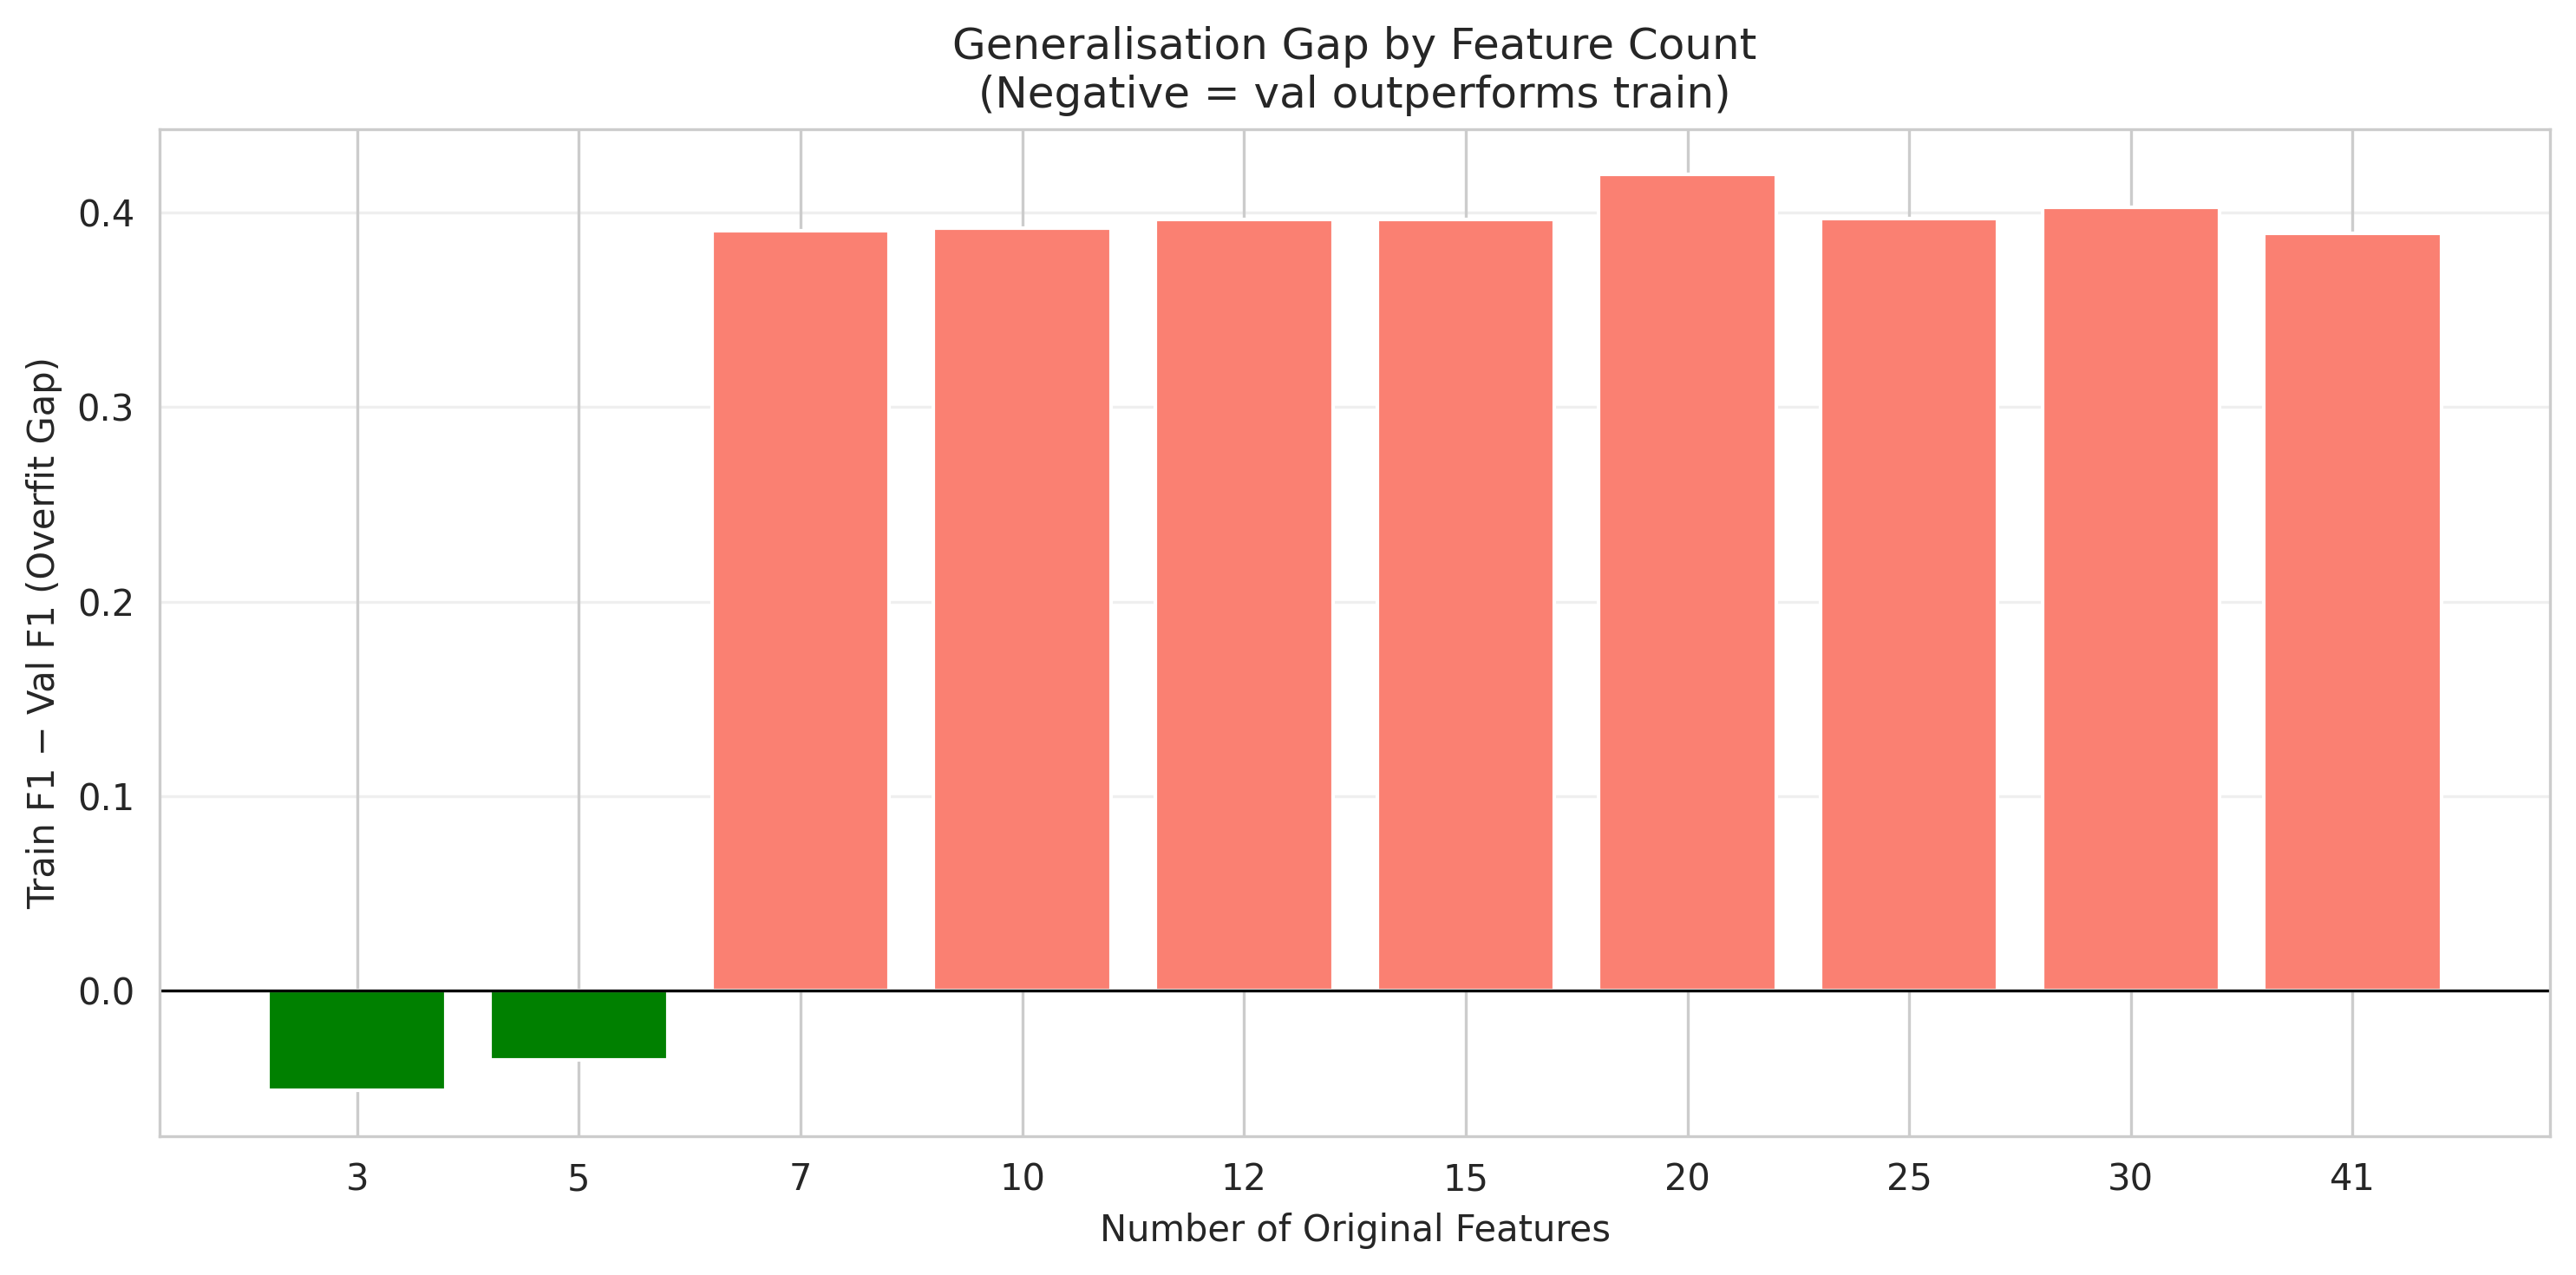

✓ Saved: ./09_per_class_f1.png


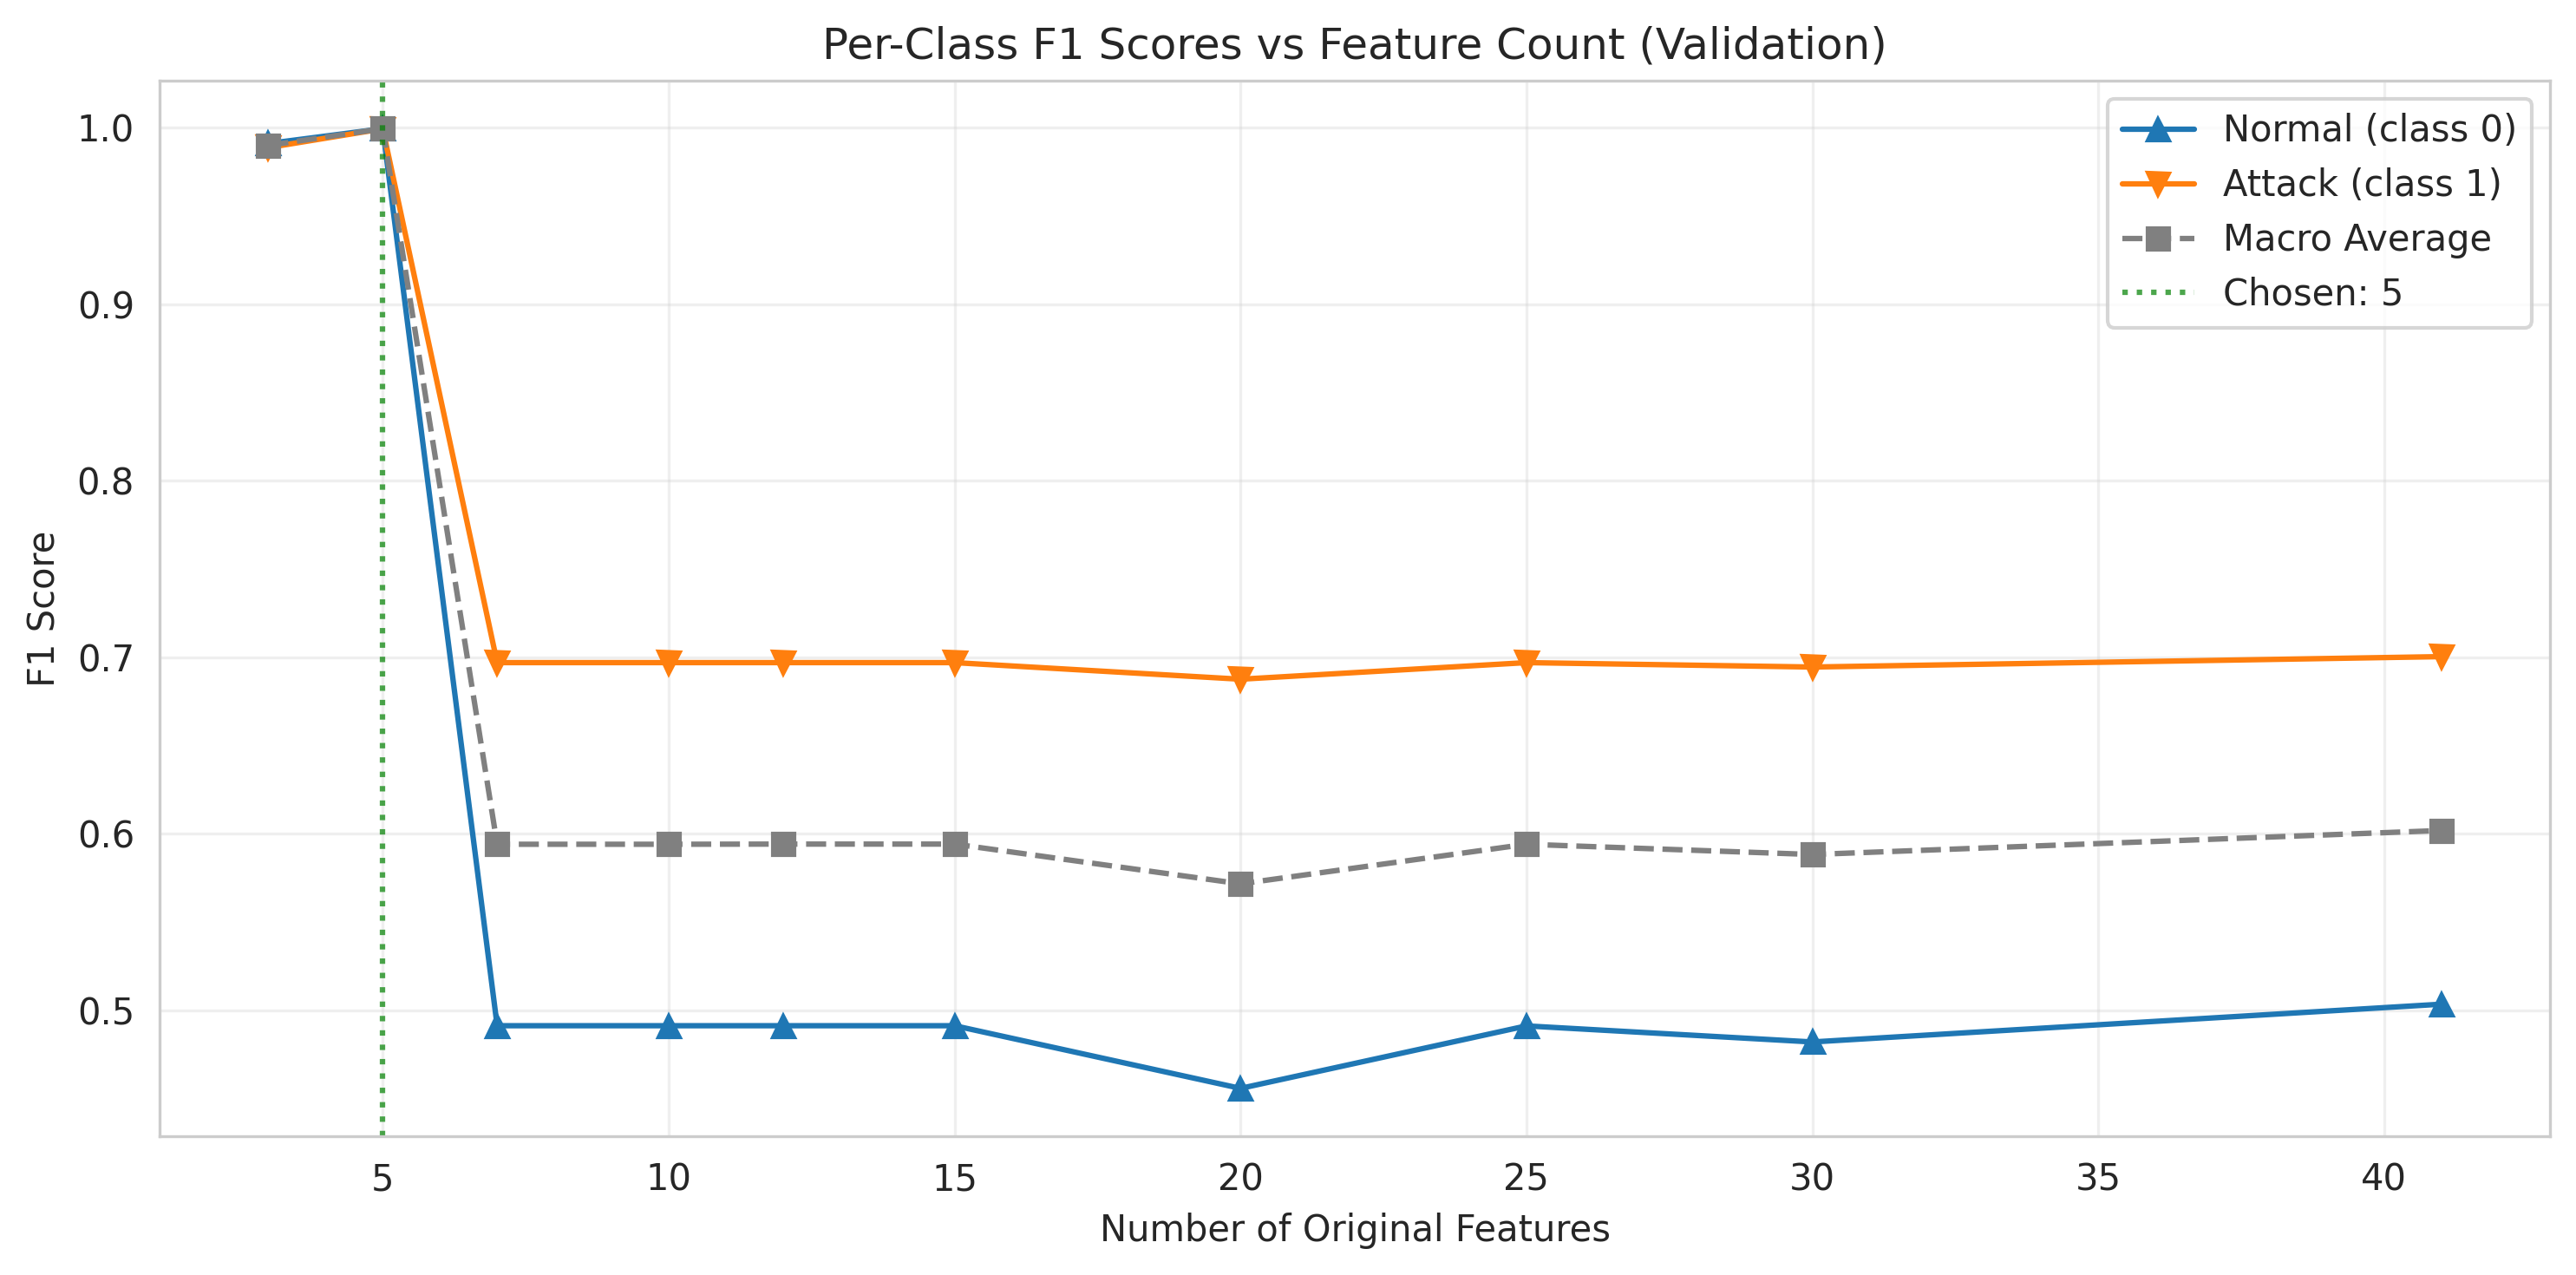

/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:123: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:123: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:125: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/src/plotting.py:125: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")


✓ Saved: ./10_mi_encoded_features.png


/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/mike/Documents/Sustainable-Machine-Learning-for-Lateral-Movement-Detection/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


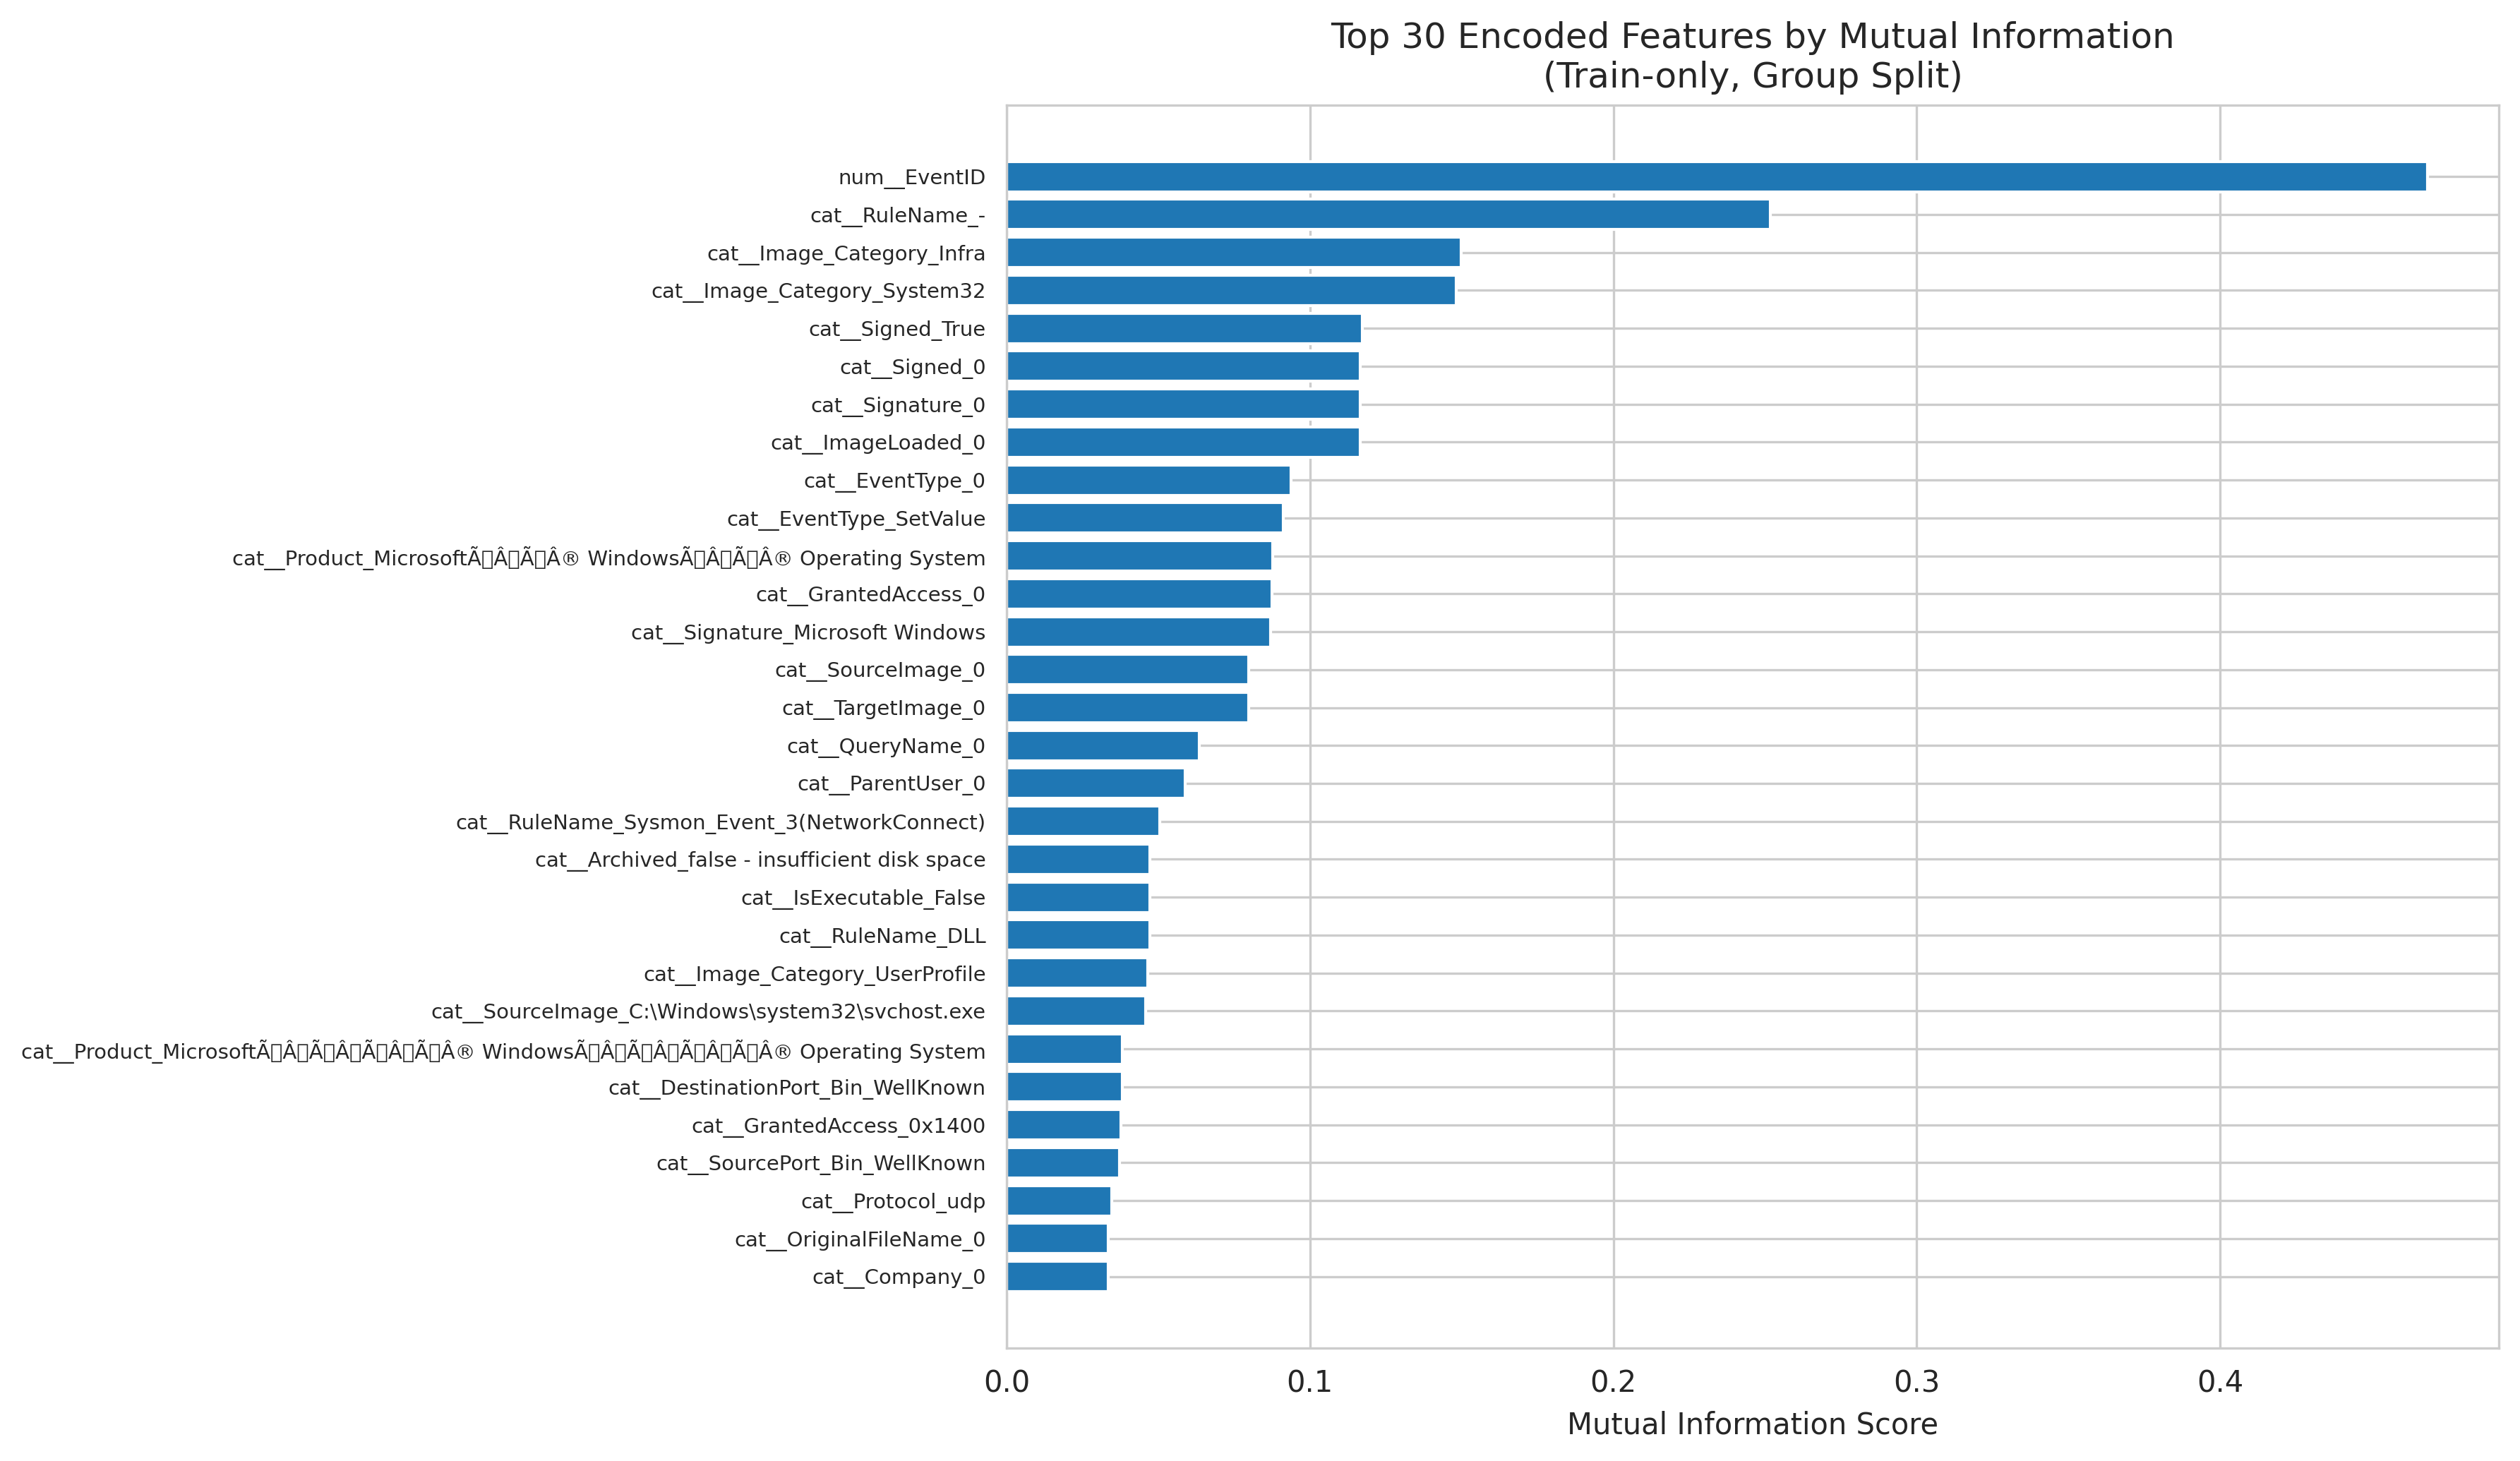

In [11]:
# Section 10: All feature selection visualisations
plot_all_selection_charts(
    summary=results["summary"],
    sweep_df=results["sweep_df"],
    mi_df=results["mi_df"],
    optimal_n=results["OPTIMAL_N"],
    pareto_threshold=results["pareto_threshold"],
    output_dir=".",
)

In [12]:
import src.preprocessing_pipeline


CREATING ALL DATASETS
Selected features (5): ['Image_Category', 'GrantedAccess', 'RuleName', 'Signed', 'SourceImage']


DATASET 1: LMD2022 NORMAL (ISOLATION FOREST)

Processing: isolation_forest_dataset.csv
  Loaded: 293,548 rows

SECTION 1: FEATURE REMOVAL (STATISTICALLY JUSTIFIED)

1a. Near-zero variance (61 features):
    Channel
    Configuration
    ConfigurationFileHash
    Correlation
    Execution_ProcessID
    ID
    Keywords
    Level
    Name
    Opcode
    PipeName
    SchemaVersion
    State
    Unnamed: 100
    Unnamed: 101
    Unnamed: 102
    Unnamed: 103
    Unnamed: 104
    Unnamed: 105
    Unnamed: 106
    Unnamed: 107
    Unnamed: 108
    Unnamed: 109
    Unnamed: 110
    Unnamed: 111
    Unnamed: 112
    Unnamed: 113
    Unnamed: 114
    Unnamed: 115
    Unnamed: 116
    Unnamed: 117
    Unnamed: 118
    Unnamed: 119
    Unnamed: 120
    Unnamed: 121
    Unnamed: 122
    Unnamed: 123
    Unnamed: 124
    Unnamed: 125
    Unnamed: 126
    Unnamed: 127
    Unnamed: 1